<a href="https://colab.research.google.com/github/rabiakrann/Ileri-Oruntu-Tanima/blob/main/ileri_oruntu_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.datasets import load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split

In [77]:
SEED = 42
K = 7
T_VALUES = [3, 4, 5, 6]
T_MAIN = 4
BLUE, ORANGE, GREEN, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

In [78]:
def z_values(v):
    return (v - v.mean()) / v.std()

def q_values(v):
    M = np.median(v)
    mad = np.median(np.abs(v - M))
    if mad == 0:
        mad = np.mean(np.abs(v - M))
    return (v - M) / mad

In [79]:
data = loadmat("/content/drive/MyDrive/Colab Notebooks/thyroidori.mat")
X_thy, y_thy = data["X"], data["y"].ravel().astype(int)
wdbc, wine, digits = load_breast_cancer(), load_wine(), load_digits()

In [80]:
datasets = {
    "Thyroid": (X_thy, [f"f{i + 1}" for i in range(X_thy.shape[1])]),
    "WDBC": (wdbc.data, list(wdbc.feature_names)),
    "Wine": (wine.data, list(wine.feature_names)),
    "Digits": (digits.data, [f"pixel_{i}" for i in range(digits.data.shape[1])]),
}

In [81]:
rule_values = {}
summary = []
for name, (X, cols) in datasets.items():
    d = X.shape[1]
    means, stds = X.mean(axis=0), X.std(axis=0)
    zm, zs = z_values(means), z_values(stds)
    qm, qs = q_values(means), q_values(stds)
    rule_values[name] = (zm, zs, qm, qs)

    print(f"\n{name}: d = {d} features, largest possible |z| = sqrt(d - 1) = {np.sqrt(d - 1):.2f}")
    for label, z, q in [("means", zm, qm), ("stds ", zs, qs)]:
        jz, jq = np.argmax(np.abs(z)), np.argmax(np.abs(q))
        print(f"  {label}: max |z| = {abs(z[jz]):7.2f} ({cols[jz][:18]})   "
              f"max |q| = {abs(q[jq]):9.2f} ({cols[jq][:18]})")
    max_z = max(np.abs(zm).max(), np.abs(zs).max())
    max_q = max(np.abs(qm).max(), np.abs(qs).max())
    summary.append((name, d, max_z, max_q))


Thyroid: d = 6 features, largest possible |z| = sqrt(d - 1) = 2.24
  means: max |z| =    1.70 (f1)   max |q| =      3.26 (f1)
  stds : max |z| =    2.15 (f1)   max |q| =      7.90 (f1)

WDBC: d = 30 features, largest possible |z| = sqrt(d - 1) = 5.39
  means: max |z| =    4.25 (worst area)   max |q| =   4521.58 (worst area)
  stds : max |z| =    4.54 (worst area)   max |q| =   8144.06 (worst area)

Wine: d = 13 features, largest possible |z| = sqrt(d - 1) = 3.46
  means: max |z| =    3.43 (proline)   max |q| =    528.38 (proline)
  stds : max |z| =    3.46 (proline)   max |q| =    584.38 (proline)

Digits: d = 64 features, largest possible |z| = sqrt(d - 1) = 7.94
  means: max |z| =    1.73 (pixel_59)   max |q| =      1.81 (pixel_59)
  stds : max |z| =    1.61 (pixel_0)   max |q| =      2.63 (pixel_0)


In [82]:

print(f"{'dataset':<9}{'max|z|':>9}{'max|q|':>10}   " + "  ".join(f"T={t}: z / q" for t in T_VALUES))
for name, d, mz, mq in summary:
    dec = "   ".join(f"{'yes' if mz > t else 'no ':>3} / {'yes' if mq > t else 'no ':<3}" for t in T_VALUES)
    print(f"{name:<9}{mz:>9.2f}{mq:>10.2f}   {dec}")

dataset     max|z|    max|q|   T=3: z / q  T=4: z / q  T=5: z / q  T=6: z / q
Thyroid       2.15      7.90   no  / yes   no  / yes   no  / yes   no  / yes
WDBC          4.54   8144.06   yes / yes   yes / yes   no  / yes   no  / yes
Wine          3.46    584.38   yes / yes   no  / yes   no  / yes   no  / yes
Digits        1.73      2.63   no  / no    no  / no    no  / no    no  / no 


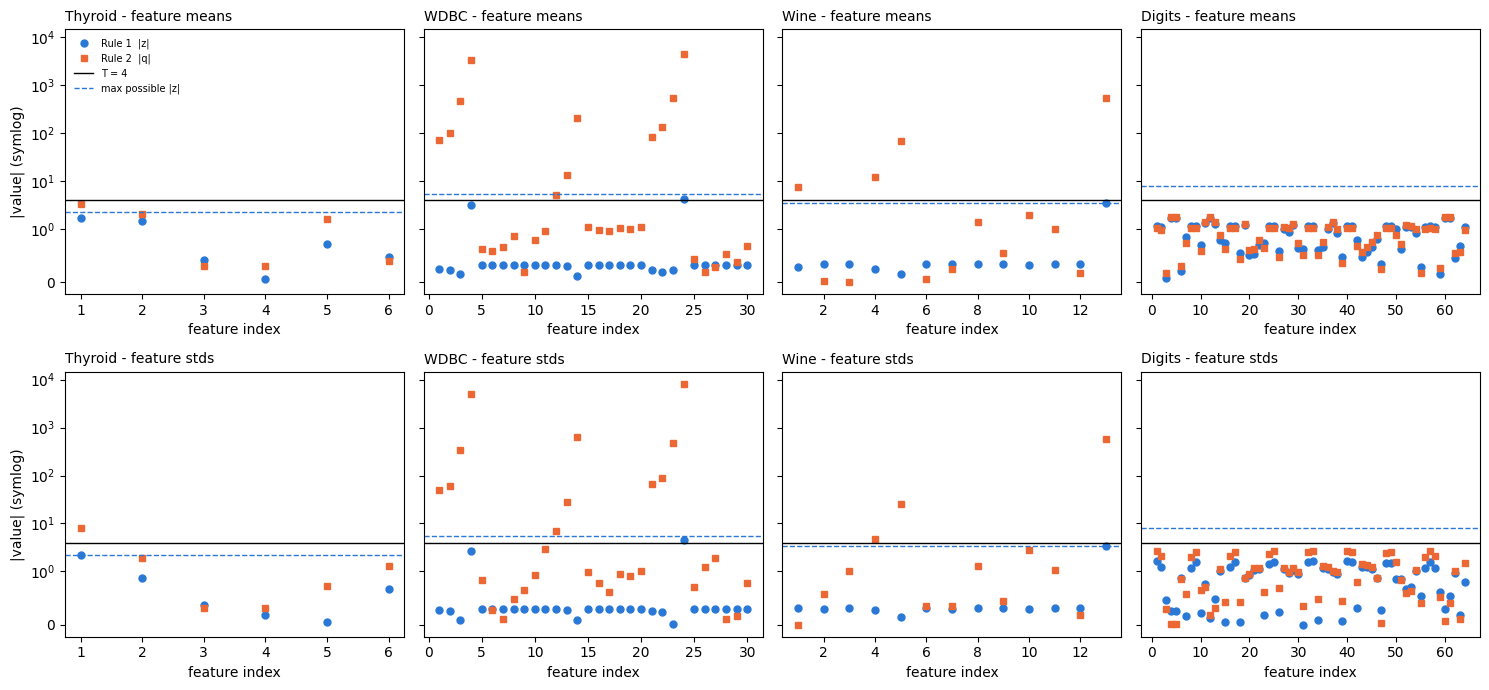

In [83]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for col, (name, (zm, zs, qm, qs)) in enumerate(rule_values.items()):
    d = len(zm)
    for row, (z, q, what) in enumerate([(zm, qm, "feature means"), (zs, qs, "feature stds")]):
        ax = axes[row, col]
        idx = np.arange(1, d + 1)
        ax.plot(idx, np.abs(z), "o", color=BLUE, ms=5, label="Rule 1  |z|")
        ax.plot(idx, np.abs(q), "s", color=ORANGE, ms=4, label="Rule 2  |q|")
        ax.axhline(T_MAIN, color="black", lw=1, label=f"T = {T_MAIN}")
        ax.axhline(np.sqrt(d - 1), color=BLUE, ls="--", lw=1, label="max possible |z|")
        ax.set_yscale("symlog", linthresh=1)
        ax.set_title(f"{name} - {what}", loc="left", fontsize=10)
        ax.set_xlabel("feature index")
axes[0, 0].set_ylabel("|value| (symlog)")
axes[1, 0].set_ylabel("|value| (symlog)")
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("4_1_rules.png", dpi=150)

In [84]:
def split_one_class(X, y, seed=SEED):
    normal, anomaly = X[y == 0], X[y == 1]
    X_train, rest_normal = train_test_split(normal, train_size=0.6, random_state=seed)
    X_rest = np.vstack([rest_normal, anomaly])
    y_rest = np.array([0] * len(rest_normal) + [1] * len(anomaly))
    X_val, X_test, y_val, y_test = train_test_split(
        X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)
    return X_train, X_val, y_val, X_test, y_test

In [85]:
def standardize(X_train, *others):
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    sd[sd == 0] = 1.0
    return [(Z - mu) / sd for Z in (X_train,) + others]

In [86]:
def robust_scale(X_train, *others):
    M = np.median(X_train, axis=0)
    mad = np.median(np.abs(X_train - M), axis=0)
    zero = mad == 0
    mad[zero] = np.mean(np.abs(X_train - M), axis=0)[zero]
    mad[mad == 0] = 1.0
    return [(Z - M) / mad for Z in (X_train,) + others]

In [87]:
def knn_score(points, train, k):
    return np.array([np.sort(np.sqrt(((train - p) ** 2).sum(axis=1)))[:k].mean() for p in points])

In [88]:
def curve_points(y_true, scores):
    P = int(np.sum(y_true == 1))
    N = len(y_true) - P
    order = np.argsort(-scores)
    s_sorted, y_sorted = scores[order], y_true[order]
    th, tp_list, fp_list = [np.inf], [0], [0]
    tp = fp = 0
    for i in range(len(s_sorted)):
        if y_sorted[i] == 1:
            tp += 1
        else:
            fp += 1
        if i == len(s_sorted) - 1 or s_sorted[i + 1] != s_sorted[i]:
            th.append(s_sorted[i])
            tp_list.append(tp)
            fp_list.append(fp)
    return np.array(th), np.array(tp_list), np.array(fp_list), P, N

In [89]:
def trapezoid(x, y):
    area = 0.0
    for i in range(1, len(x)):
        area += (x[i] - x[i - 1]) * (y[i] + y[i - 1]) / 2
    return area

In [90]:
def roc(y_true, scores):
    th, tp, fp, P, N = curve_points(y_true, scores)
    return fp / N, tp / P

In [91]:
def pr(y_true, scores):
    th, tp, fp, P, N = curve_points(y_true, scores)
    recall = tp / P
    precision = np.ones(len(tp))
    precision[1:] = tp[1:] / (tp[1:] + fp[1:])
    return recall, precision

In [92]:
def average_precision(recall, precision):
    return sum((recall[i] - recall[i - 1]) * precision[i] for i in range(1, len(recall)))

In [93]:
def eer(y_true, scores):
    th, tp, fp, P, N = curve_points(y_true, scores)
    fpr, fnr = fp / N, 1 - tp / P
    diff = fpr - fnr                          # goes from -1 (th = +inf) to +1 (lowest th)
    i = int(np.argmax(diff >= 0))             # first point where FPR >= FNR
    t = diff[i - 1] / (diff[i - 1] - diff[i])
    rate = fpr[i - 1] + t * (fpr[i] - fpr[i - 1])
    th_x = th[i] if i == 1 else np.exp(np.log(th[i - 1]) + t * (np.log(th[i]) - np.log(th[i - 1])))
    j = 1 + int(np.argmin(np.abs(diff[1:])))  # point 0 (th = +inf) is not a usable threshold
    return rate, j, fpr, fnr, th, th_x

In [94]:
def confusion(y_true, y_pred):
    tn = fp = fn = tp = 0
    for t, p in zip(y_true, y_pred):
        if t == 0 and p == 0:
            tn += 1
        elif t == 0 and p == 1:
            fp += 1
        elif t == 1 and p == 0:
            fn += 1
        else:
            tp += 1
    return tn, fp, fn, tp

In [95]:
def f1_score(tn, fp, fn, tp):
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    return 2 * precision * recall / (precision + recall) if precision + recall else 0

In [96]:
def balanced_accuracy(tn, fp, fn, tp):
    return (tp / (tp + fn) + tn / (tn + fp)) / 2

In [97]:
X_train, X_val, y_val, X_test, y_test = split_one_class(X_thy, y_thy)
X_tr_raw, X_va_raw, X_te_raw = X_train.copy(), X_val.copy(), X_test.copy()
prevalence = np.mean(y_test)
print(f"anomaly ratio: whole dataset = {np.mean(y_thy):.4f}, test set = {prevalence:.4f} "
      f"(60% of the normals are used for training)")
print(f"test: {np.sum(y_test == 0)} normal + {np.sum(y_test == 1)} anomaly")

anomaly ratio: whole dataset = 0.0247, test set = 0.0600 (60% of the normals are used for training)
test: 736 normal + 47 anomaly


In [98]:
transforms = {
    "raw (no transformation)": (X_tr_raw, X_te_raw),
    "z-score": tuple(standardize(X_tr_raw, X_te_raw)),
    "median-MAD": tuple(robust_scale(X_tr_raw, X_te_raw)),
}
print(f"\n{'transformation':<26}{'ROC-AUC':>9}{'PR-AUC':>9}{'EER':>8}")
for name, (A, B) in transforms.items():
    sc = knn_score(B, A, K)
    R, Pr = pr(y_test, sc)
    print(f"{name:<26}{trapezoid(*roc(y_test, sc)):>9.3f}{trapezoid(R, Pr):>9.3f}{eer(y_test, sc)[0]:>8.3f}")


transformation              ROC-AUC   PR-AUC     EER
raw (no transformation)       0.973    0.724   0.085
z-score                       0.991    0.857   0.035
median-MAD                    0.992    0.869   0.034


In [99]:
X_train, X_val, X_test = standardize(X_tr_raw, X_va_raw, X_te_raw)
s_val = knn_score(X_val, X_train, K)
s_test = knn_score(X_test, X_train, K)

In [100]:
rng = np.random.default_rng(SEED)
scores = {                                   # same scores as Odev 3.3
    "k-NN, standardized": s_test,
    "k-NN, not standardized": knn_score(X_te_raw, X_tr_raw, K),
    "single feature f3 (|z|)": np.abs(X_test[:, 2]),
    "single feature f1 (|z|)": np.abs(X_test[:, 0]),
    "random score": rng.random(len(y_test)),
}
colors = [BLUE, ORANGE, GREEN, YELLOW, "gray"]

In [101]:
results = {}
print(f"\n{'score':<26}{'ROC-AUC':>9}{'PR-AUC':>9}{'AP':>8}{'EER':>8}")
for name, sc in scores.items():
    roc_auc = trapezoid(*roc(y_test, sc))
    R, Pr = pr(y_test, sc)
    pr_auc = trapezoid(R, Pr)
    ap = average_precision(R, Pr)
    e = eer(y_test, sc)[0]
    results[name] = (roc_auc, pr_auc, ap, e)
    print(f"{name:<26}{roc_auc:>9.3f}{pr_auc:>9.3f}{ap:>8.3f}{e:>8.3f}")
print(f"random classifier baseline: ROC-AUC = 0.5, PR-AUC = anomaly ratio = {prevalence:.3f}")


score                       ROC-AUC   PR-AUC      AP     EER
k-NN, standardized            0.991    0.857   0.859   0.035
k-NN, not standardized        0.973    0.724   0.727   0.085
single feature f3 (|z|)       0.850    0.234   0.257   0.198
single feature f1 (|z|)       0.495    0.078   0.075   0.478
random score                  0.477    0.074   0.076   0.514
random classifier baseline: ROC-AUC = 0.5, PR-AUC = anomaly ratio = 0.060


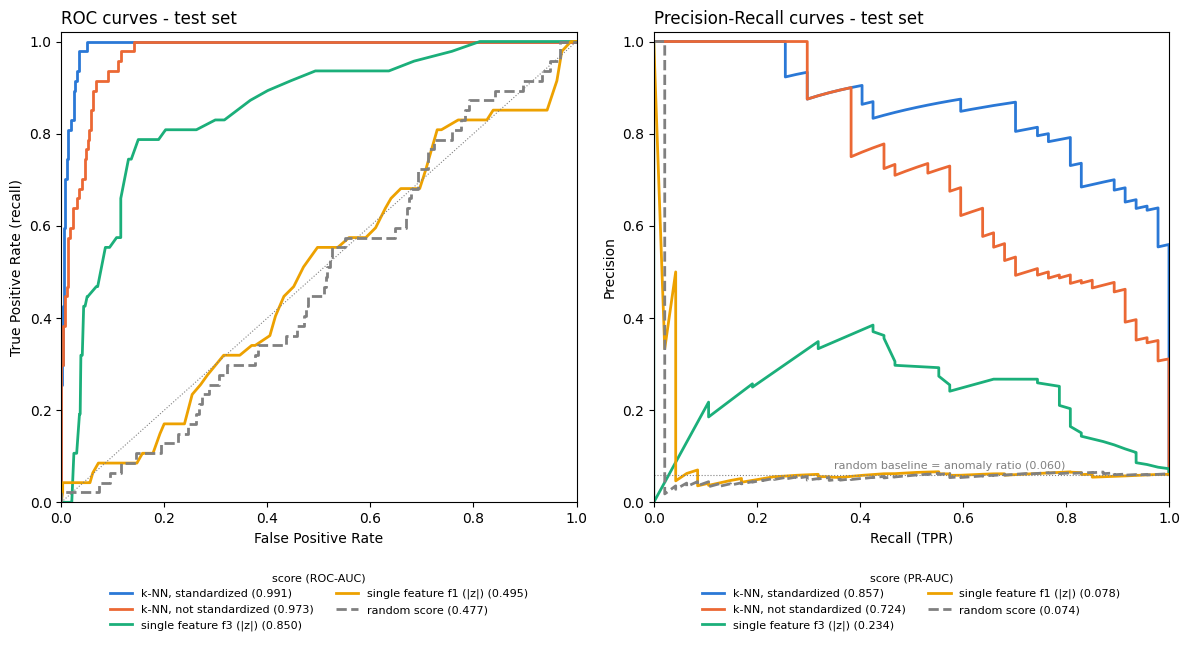

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.6))
for (name, sc), c in zip(scores.items(), colors):
    ls = "--" if name == "random score" else "-"
    f, t = roc(y_test, sc)
    axes[0].plot(f, t, color=c, lw=2, ls=ls, label=f"{name} ({results[name][0]:.3f})")
    R, Pr = pr(y_test, sc)
    axes[1].plot(R, Pr, color=c, lw=2, ls=ls, label=f"{name} ({results[name][1]:.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", lw=0.8, ls=":")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (recall)")
axes[0].set_title("ROC curves - test set", loc="left")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=8,
               title="score (ROC-AUC)", title_fontsize=8)
axes[1].axhline(prevalence, color="gray", lw=0.8, ls=":")
axes[1].annotate(f"random baseline = anomaly ratio ({prevalence:.3f})", (0.35, prevalence),
                 xytext=(0, 4), textcoords="offset points", fontsize=8, color="gray")
axes[1].set_xlabel("Recall (TPR)")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves - test set", loc="left")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=8,
               title="score (PR-AUC)", title_fontsize=8)
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig("4_2_roc_vs_pr.png", dpi=150)

In [103]:
n_anom = int(np.sum(y_test == 1))
idx_n, idx_a = np.where(y_test == 0)[0], np.where(y_test == 1)[0]
ratio_rows = []
print(f"{'normals':>8}{'ratio':>8} | " + " | ".join(f"{n[:18]:^20}" for n in
      ["k-NN, standardized", "single feature f3 (|z|)", "random score"]))
print(f"{'':>17}| " + " | ".join(f"{'ROC':>9}{'PR':>9}  " for _ in range(3)))
for n_norm in [47, 188, 470, len(idx_n)]:
    repeats = 1 if n_norm == len(idx_n) else 20
    vals = {n: [] for n in ["k-NN, standardized", "single feature f3 (|z|)", "random score"]}
    for r in range(repeats):
        sel = np.concatenate([np.random.default_rng(r).choice(idx_n, n_norm, replace=False), idx_a])
        for n in vals:
            sc = scores[n][sel]
            vals[n].append((trapezoid(*roc(y_test[sel], sc)), trapezoid(*pr(y_test[sel], sc))))
    ratio = n_anom / (n_anom + n_norm)
    means = {n: np.mean(v, axis=0) for n, v in vals.items()}
    ratio_rows.append((n_norm, ratio, means))
    print(f"{n_norm:>8}{ratio:>8.3f} | " + " | ".join(f"{m[0]:>9.3f}{m[1]:>9.3f}  " for m in means.values()))

 normals   ratio |  k-NN, standardized  |  single feature f3   |     random score    
                 |       ROC       PR   |       ROC       PR   |       ROC       PR  
      47   0.500 |     0.993    0.992   |     0.855    0.801   |     0.477    0.479  
     188   0.200 |     0.991    0.955   |     0.847    0.507   |     0.482    0.200  
     470   0.091 |     0.991    0.898   |     0.845    0.307   |     0.478    0.101  
     736   0.060 |     0.991    0.857   |     0.850    0.234   |     0.477    0.074  


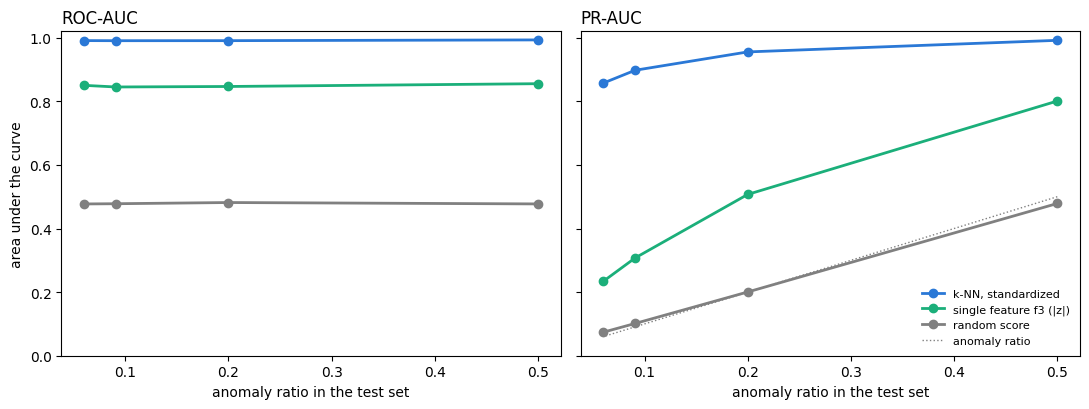

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ratios = [r[1] for r in ratio_rows]
for n, c in zip(["k-NN, standardized", "single feature f3 (|z|)", "random score"], [BLUE, GREEN, "gray"]):
    axes[0].plot(ratios, [r[2][n][0] for r in ratio_rows], "o-", color=c, lw=2, label=n)
    axes[1].plot(ratios, [r[2][n][1] for r in ratio_rows], "o-", color=c, lw=2, label=n)
axes[1].plot(ratios, ratios, ":", color="gray", lw=1, label="anomaly ratio")
axes[0].set_title("ROC-AUC", loc="left")
axes[1].set_title("PR-AUC", loc="left")
for ax in axes:
    ax.set_xlabel("anomaly ratio in the test set")
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("area under the curve")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("4_3_class_ratio.png", dpi=300)

In [105]:
eer_rate, j, fpr, fnr, th, th_x = eer(y_test, s_test)
eer_th = th[j]
print(f"EER (linear interpolation between two ROC points) = {eer_rate:.4f}")
print(f"closest real threshold (smallest |FPR - FNR|): Th = {eer_th:.3f}, "
      f"FPR = {fpr[j]:.4f}, FNR = {fnr[j]:.4f}")

EER (linear interpolation between two ROC points) = 0.0353
closest real threshold (smallest |FPR - FNR|): Th = 1.724, FPR = 0.0353, FNR = 0.0426


In [106]:
cand = np.unique(s_val)
th_ba = cand[int(np.argmax([balanced_accuracy(*confusion(y_val, (s_val > t).astype(int))) for t in cand]))]
th_f1 = cand[int(np.argmax([f1_score(*confusion(y_val, (s_val > t).astype(int))) for t in cand]))]
print(f"\n{'threshold':<22}{'Th':>8}{'FPR':>8}{'FNR':>8}{'TN':>6}{'FP':>5}{'FN':>5}{'TP':>5}")
for name, t, pred in [("closest to EER (test)", eer_th, (s_test >= eer_th).astype(int)),
                      ("Th_BA (Odev 3)", th_ba, (s_test > th_ba).astype(int)),
                      ("Th_F1 (Odev 3)", th_f1, (s_test > th_f1).astype(int))]:
    tn, fp, fn, tp = confusion(y_test, pred)
    print(f"{name:<22}{t:>8.3f}{fp / (fp + tn):>8.3f}{fn / (fn + tp):>8.3f}{tn:>6}{fp:>5}{fn:>5}{tp:>5}")


threshold                   Th     FPR     FNR    TN   FP   FN   TP
closest to EER (test)    1.724   0.035   0.043   710   26    2   45
Th_BA (Odev 3)           1.140   0.090   0.000   670   66    0   47
Th_F1 (Odev 3)           2.223   0.016   0.191   724   12    9   38



saved figures: 4_1_rules.png, 4_2_roc_vs_pr.png, 4_3_class_ratio.png, 4_4_eer.png


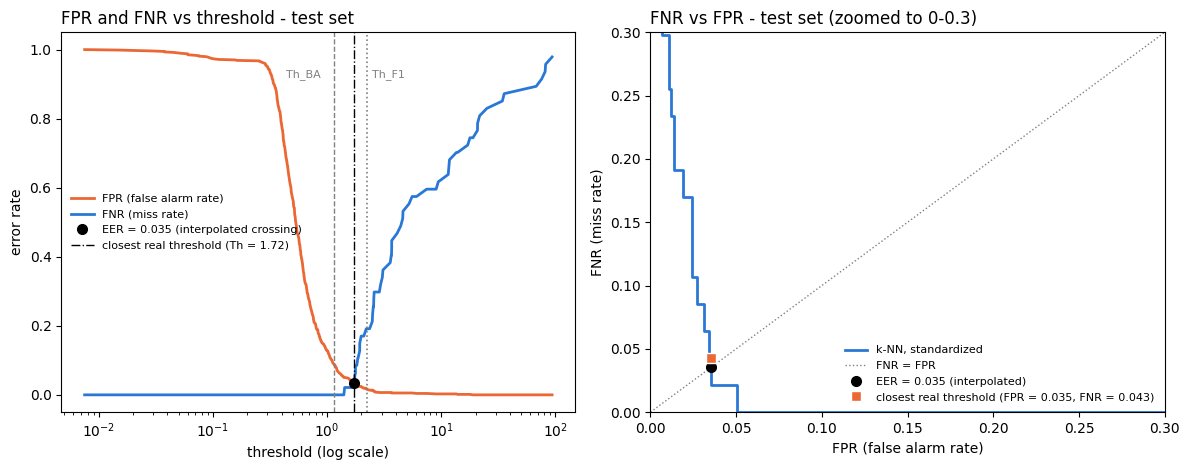

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
ax.plot(th[1:], fpr[1:], color=ORANGE, lw=2, label="FPR (false alarm rate)")
ax.plot(th[1:], fnr[1:], color=BLUE, lw=2, label="FNR (miss rate)")
ax.plot(th_x, eer_rate, "o", color="black", ms=7, label=f"EER = {eer_rate:.3f} (interpolated crossing)")
ax.axvline(eer_th, color="black", ls="-.", lw=1, label=f"closest real threshold (Th = {eer_th:.2f})")
ax.axvline(th_ba, color="gray", ls="--", lw=1)
ax.axvline(th_f1, color="gray", ls=":", lw=1.2)
ax.annotate("Th_BA", (th_ba, 0.92), xytext=(-34, 0), textcoords="offset points", fontsize=8, color="gray")
ax.annotate("Th_F1", (th_f1, 0.92), xytext=(4, 0), textcoords="offset points", fontsize=8, color="gray")
ax.set_xscale("log")
ax.set_xlabel("threshold (log scale)")
ax.set_ylabel("error rate")
ax.set_title("FPR and FNR vs threshold - test set", loc="left")
ax.legend(frameon=False, fontsize=8, loc="center left")
ax = axes[1]
ax.plot(fpr, fnr, color=BLUE, lw=2, label="k-NN, standardized")
ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1, label="FNR = FPR")
ax.plot(eer_rate, eer_rate, "o", color="black", ms=7, label=f"EER = {eer_rate:.3f} (interpolated)")
ax.plot(fpr[j], fnr[j], "s", color=ORANGE, ms=7, mec="white",
        label=f"closest real threshold (FPR = {fpr[j]:.3f}, FNR = {fnr[j]:.3f})")
ax.set_xlim(0, 0.3)
ax.set_ylim(0, 0.3)
ax.set_xlabel("FPR (false alarm rate)")
ax.set_ylabel("FNR (miss rate)")
ax.set_title("FNR vs FPR - test set (zoomed to 0-0.3)", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("4_4_eer.png", dpi=150)
print("\nsaved figures: 4_1_rules.png, 4_2_roc_vs_pr.png, 4_3_class_ratio.png, 4_4_eer.png")